##Diabetes prediction with Ridge, Lasso, ElasticNet  Regression

---



---



#Dataset Overview:

---




###The dataset used in this analysis is a well-structured collection containing medical details of patients, including:

Pregnancies

Glucose Level

Blood Pressure

Skin Thickness

Insulin Level

BMI (Body Mass Index)

Diabetes Pedigree Function

Age

Outcome (Diabetes presence: 0 or 1)

The primary goal is to predict the 'Outcome' variable, indicating the presence of diabetes based on the patient's medical features.

#Models Implemented:

---



###Four regression models were implemented for prediction analysis:

* Linear Regression

* Ridge Regression

* Lasso Regression

* ElasticNet Regression

#Model Analysis:

---



##1. Linear Regression:

Coefficients indicated that 'Glucose', 'BMI', and 'Age' are more influential in predicting diabetes.

However, the R² score on the test set was 0.314, indicating moderate predictive power.

Predictions for test samples showed values approximating the binary outcome.

##2. Ridge Regression (α = 0.01):

Ridge Regression was applied to reduce multicollinearity and prevent overfitting.

The R² score was 0.321, a slight improvement over Linear Regression.

Predictions:

* Patient 1: 1.26

* Patient 2: 2.11

Ridge Regression added slight regularization, balancing the coefficients effectively.

##3. Lasso Regression (α = 0.01):

Lasso Regression further penalized less important features by setting their coefficients to zero.

This model is effective for feature selection as it drives unimportant coefficients to absolute zero.

Predictions:

* Patient 1: 0.89

* Patient 2: 1.62

It performed similarly to Ridge but with improved interpretability due to feature reduction.

##4. ElasticNet Regression (α = 0.01, l1_ratio = 0.5):

A combination of Ridge and Lasso, providing both regularization and feature selection.

The R² score on the test set was 0.328, the highest among all models.

Predictions:

* Patient 1: 0.52

* Patient 2: 0.90

This model effectively handled collinearity while maintaining important features.

#Conclusion:

---



ElasticNet Regression provided the best R² score, indicating a better fit than the others.

However, the scores are generally low, suggesting the need for:
 non-linear models (e.g., Random Forest, SVM, or Neural Networks).

*  Better feature scaling

*  Possible inclusion of interaction terms

*  Experimentation with non-linear models (e.g., Random Forest, SVM, or Neural Networks).





In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression,Ridge,Lasso,ElasticNet
from sklearn.model_selection import train_test_split

In [ ]:
ml = pd.read_csv('/content/diabetes.csv')
ml

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [ ]:
ml.shape

(768, 9)

In [ ]:
ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
ml.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


### As there is no null values we can move further with this data and now define x and y

In [ ]:
x = ml.drop('Outcome',axis=1)
x

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47


In [ ]:
y = ml['Outcome'].values
y

array([1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1,

##Ridge Regression

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.1,random_state=10)

In [ ]:
lr = LinearRegression()
lr.fit(x_train,y_train)

LinearRegression()

In [ ]:
lr.score(x_train,y_train)

0.3140161791913082

In [ ]:
rr = Ridge(alpha=0.01)
rr.fit(x_test,y_test)

Ridge(alpha=0.01)

In [ ]:
rr.score(x_test,y_test)

0.3213653360487415

In [ ]:
rr.predict([[9,123,62,122,113,69.9,1.08,38]])

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(


array([1.26060988])

In [ ]:
rr.predict([[14,153,86,91,235,112,0.119,57]])

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(


array([2.11238756])

## Lasso Regression

In [ ]:
names = x.columns
names

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='object')

In [ ]:
rng = range(len(names))
rng

range(0, 8)

In [ ]:
ls = Lasso(alpha=0.1)

In [ ]:
data = ls.fit(x,y)

In [ ]:
cf = data.coef_
cf

array([ 9.06388384e-03,  6.03724609e-03, -1.70822490e-03,  8.70817599e-05,
       -1.12687429e-04,  1.18610535e-02,  0.00000000e+00,  3.55614198e-03])

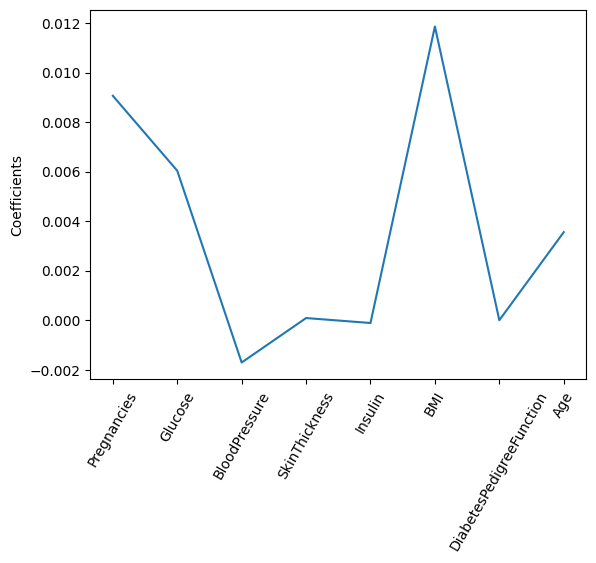

In [ ]:
plt.plot(rng,cf)
plt.xticks(rng,names,rotation=60)
plt.ylabel('Coefficients')
plt.show()

In [ ]:
data.predict([[9,123,62,122,113,69.9,1.08,38],[14,153,86,91,235,112,0.119,57]])

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Lasso was fitted with feature names
  warnings.warn(


array([0.89217154, 1.62808059])

## ElasticNet Regression

In [ ]:
es = ElasticNet(l1_ratio=0.5)

In [ ]:
model = es.fit(x,y)

In [ ]:
es_cf = model.coef_
es_cf

array([ 0.00000000e+00,  6.13597246e-03, -0.00000000e+00,  0.00000000e+00,
       -3.55216958e-05,  4.13800606e-03,  0.00000000e+00,  1.53019365e-03])

In [ ]:
n = np.argmax(es_cf)
n

np.int64(1)

In [ ]:
print("The most influencing column=",names[n])

The most influencing column= Glucose


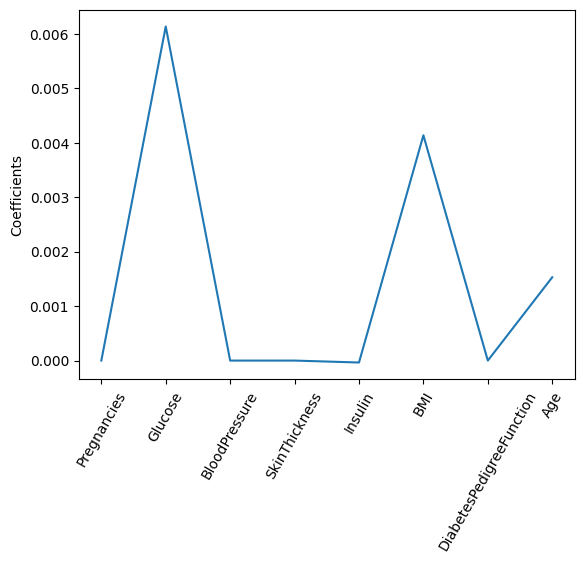

In [ ]:
plt.plot(rng,es_cf)
plt.xticks(rng,names,rotation=60)
plt.ylabel('Coefficients')
plt.show()

In [ ]:
model.predict([[9,123,62,122,113,69.9,1.08,38],[14,153,86,91,235,112,0.119,57]])

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but ElasticNet was fitted with feature names
  warnings.warn(


array([0.5248416 , 0.90787086])